In [2]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from utilz.plotting_utilz import * 

In [3]:
results_dir = "../vit_results_v3/"
figures_dir = "./paper_figs_v3/"
if not os.path.exists(figures_dir):
    os.makedirs(figures_dir)
    os.makedirs(os.path.join(figures_dir, "main"))
    os.makedirs(os.path.join(figures_dir, "supplementary"))

## Fig A1 - Performance Heatmap for Task Relevance Projection

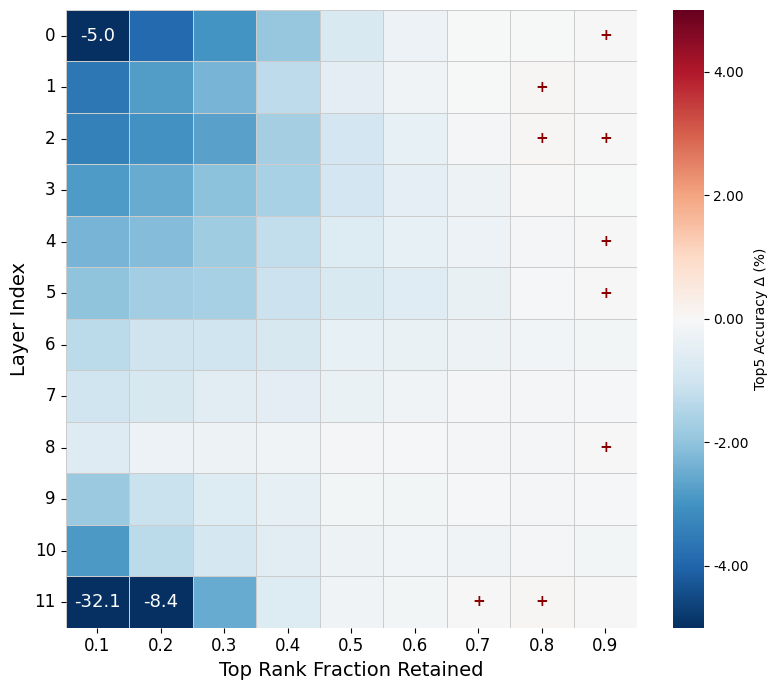

In [4]:
MODEL_NAME = 'vit_b_16'
PROJ_TYPE = 'task'
METRIC = 'delta_top5'
RENORM = True

result_df = pd.read_csv(f"{results_dir}/{MODEL_NAME}/{PROJ_TYPE}_cache/single_layer_{proj_to_filename[PROJ_TYPE]}_utility_curves.csv")
res = extract_layer_rank_grid(result_df, renorm=RENORM, null_proj=False, metric=METRIC)
res = res * 100  # convert to percentage points for easier interpretation
layer_inds = extract_layer_inds_from_data(result_df)
rank_fracs = extract_rank_fracs_from_data(result_df)


fig, ax = plt.subplots(1, 1, figsize=(8, 7))

# tight symmetric clim to reveal near-zero structure
clim = 5
cmap_limits = [-clim, clim]

topk = str(METRIC).split('_')[-1]

sns.heatmap(
    res,
    xticklabels=np.round(rank_fracs, 2),
    yticklabels=layer_inds,
    ax=ax,
    cmap='RdBu_r',
    center=0,
    vmin=cmap_limits[0],
    vmax=cmap_limits[1],
    cbar_kws={'label': f'{topk.capitalize()} Accuracy Δ (%)', 'format': '%.2f'},
    linewidths=0.6,
    linecolor='#cccccc',
)

# annotate positive cells with actual value
for i in range(res.shape[0]):
    for j in range(res.shape[1]):
        val = res[i, j]
        if val > 0:
            ax.text(j + 0.5, i + 0.5, f'+',
                    ha='center', va='center', color='darkred',
                    fontsize=11, fontweight='bold')
        elif val < -clim:
            # mark clipped cells so reader knows they're saturated
            ax.text(j + 0.5, i + 0.5, f'{val:.1f}',
                    ha='center', va='center', color='white',
                    fontsize=13)



# ax.set_title(f"{model_to_title[MODEL_NAME]} {proj_to_title[PROJ_TYPE]} Projection: {metric_to_title[METRIC]} ")
ax.set_xlabel("Top Rank Fraction Retained", fontsize=14)
ax.set_ylabel("Layer Index", fontsize=14)

ax.tick_params(axis='x', labelrotation=0, labelsize=12)
ax.tick_params(axis='y', labelrotation=0, labelsize=12)

plt.tight_layout()
plt.savefig(f"{figures_dir}/main/A1_{MODEL_NAME}_{PROJ_TYPE}_{METRIC}_heatmap.png", dpi=300)
plt.show()

## Fig A2 - Layerwise grid for all projection types

In [5]:
global_res = pd.read_csv(f"{results_dir}/{MODEL_NAME}/task_global_results/fixed.csv").iloc[0]

BASELINE = {
    'top1': global_res['top1'],
    'top5': global_res['top5'],
}



In [6]:
proj_to_title['task'] = 'Task Sensitive'
proj_to_filename['task'] = 'task_relevance'


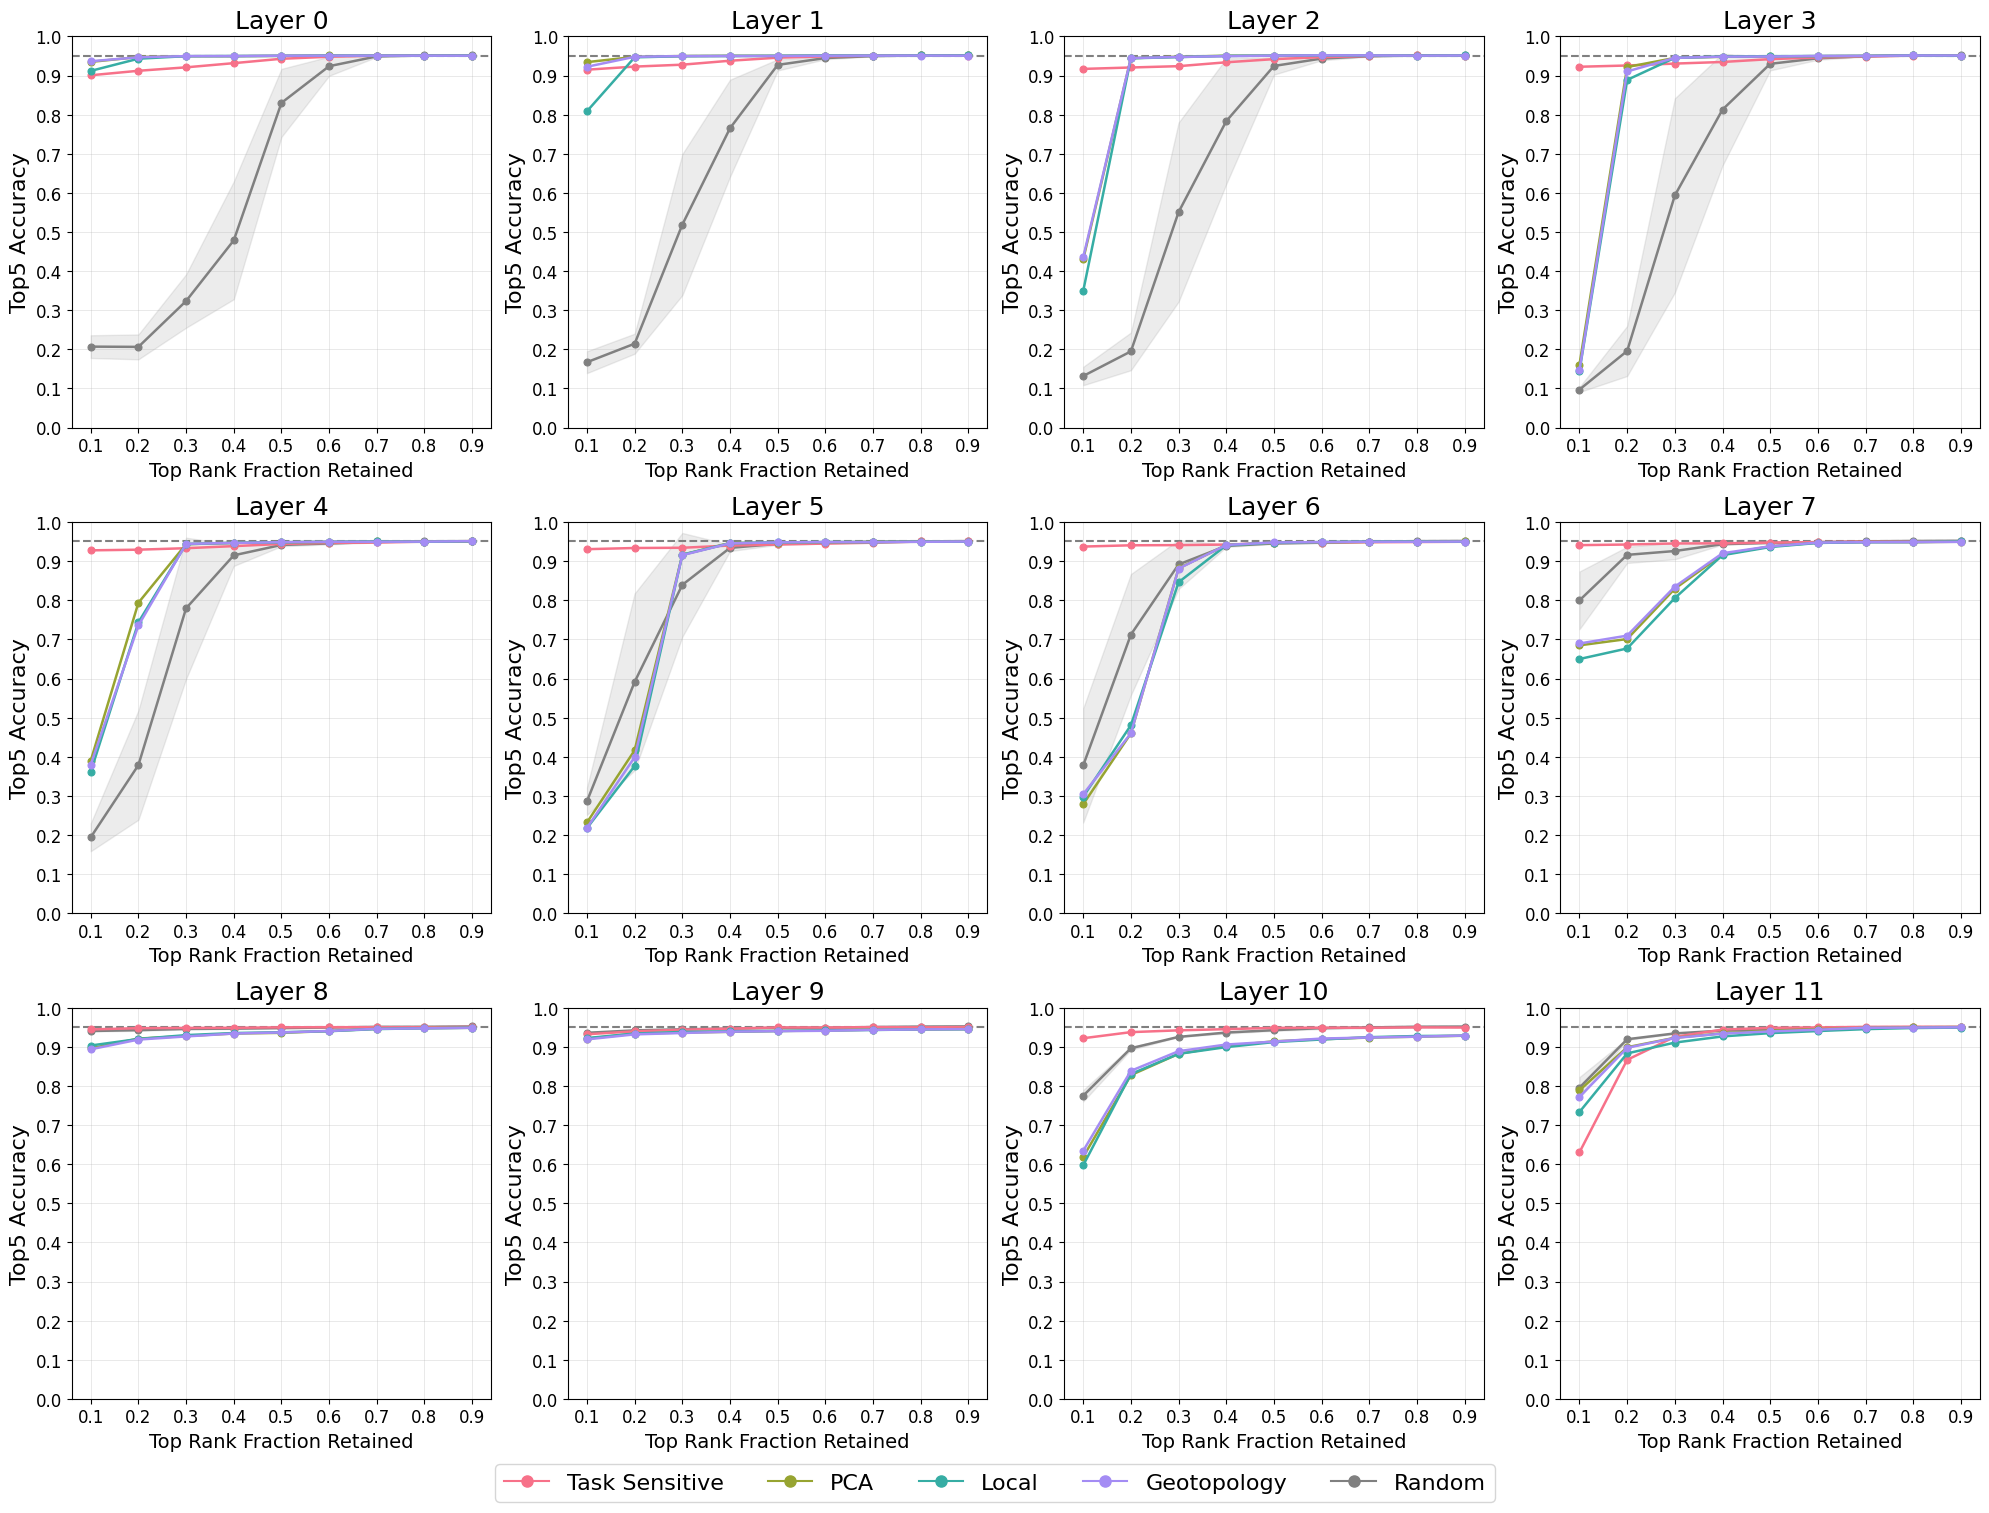

In [7]:
proj_to_filename['random'] = 'random'
proj_to_title['random'] = 'Random'
proj_colors.append('gray')

projs_to_plot = proj_types
METRIC = 'top5'
# n_layer grids for rankwise curves, one for each projection type
fig, axs = plt.subplots(3,4, figsize=(20, 16))
y_min, y_max = (0, 1.0)

for li in layer_inds:
    ax = axs[li // 4, li % 4]
    plus_count = np.zeros(len(rank_fracs), dtype=int)

    for pi, proj_type in enumerate(projs_to_plot):
        result_df = pd.read_csv(f"{results_dir}/{MODEL_NAME}/{proj_type}_cache/single_layer_{proj_to_filename[proj_type]}_utility_curves.csv")
        res = extract_layer_rank_grid(result_df, renorm=RENORM, null_proj=False, metric=METRIC)

        y_vals = res[li]
        ax.plot(
            rank_fracs, y_vals,
            color=proj_colors[pi],
            marker='o', markersize=5,
            markerfacecolor=proj_colors[pi],
            markeredgewidth=0.8,
            linewidth=1.8,
            label=proj_to_title[proj_type],
            zorder=3,
        )
        

    # add random baseline for each layer
    random_y_seeds = []
    for rep_i in range(3):
        result_df_random = pd.read_csv(f"{results_dir}/{MODEL_NAME}/random_cache_seed{rep_i}/single_layer_random_utility_curves.csv")
        random_y_vals = extract_layer_rank_grid(result_df_random, renorm=RENORM, null_proj=False, metric=METRIC)[li]
        random_y_seeds.append(random_y_vals)
    #avg across seeds and error bars for std dev across seeds
    random_y_avg = np.mean(random_y_seeds, axis=0)
    random_y_std = np.std(random_y_seeds, axis=0)
    ax.plot(
        rank_fracs, random_y_avg,
        color='gray',
        marker='o', markersize=5,
        markerfacecolor='gray',
        markeredgewidth=0.8,
        linewidth=1.8,
        label='Random',
        zorder=2,
    )
    ax.fill_between(
        rank_fracs,
        random_y_avg - random_y_std,
        random_y_avg + random_y_std,
        color='gray',
        alpha=0.15,
        zorder=1,
    )

    # add horizontal line for baseline
    ax.axhline(BASELINE[METRIC], color='gray', linestyle='--', label='Baseline')

    # add grid
    ax.grid(True, which='both', linewidth=0.5, alpha=0.4)
    ax.set_xticks(rank_fracs)
    ax.set_xticklabels([f"{rf:.1f}" for rf in rank_fracs], fontsize=12)

    ax.set_ylim(y_min, y_max)
    ax.set_yticks(np.arange(y_min, y_max+0.1, 0.1))
    ax.set_yticklabels([f"{y:.1f}" for y in np.arange(y_min, y_max+0.1, 0.1)], fontsize=12)

    ax.set_title(f"Layer {li}", fontsize=18)
    ax.set_xlabel("Top Rank Fraction Retained", fontsize=14)
    ax.set_ylabel(f"{METRIC.capitalize()} Accuracy", fontsize=16)

    # remove legend
    ax.legend().remove()
    
# add horizontal legend at the top
handles = [plt.Line2D([0], [0], color=proj_colors[pi], marker='o', markersize=8, label=proj_to_title[proj_type]) for pi, proj_type in enumerate(projs_to_plot+['random'])]
fig.legend(handles=handles, loc='lower center', ncol=len(projs_to_plot)+1, fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(f"{figures_dir}/main/A2_{MODEL_NAME}_{METRIC}_layerwise_curves_with_random.png", dpi=300)
plt.show() 
    

## Fig A3 - Global projections

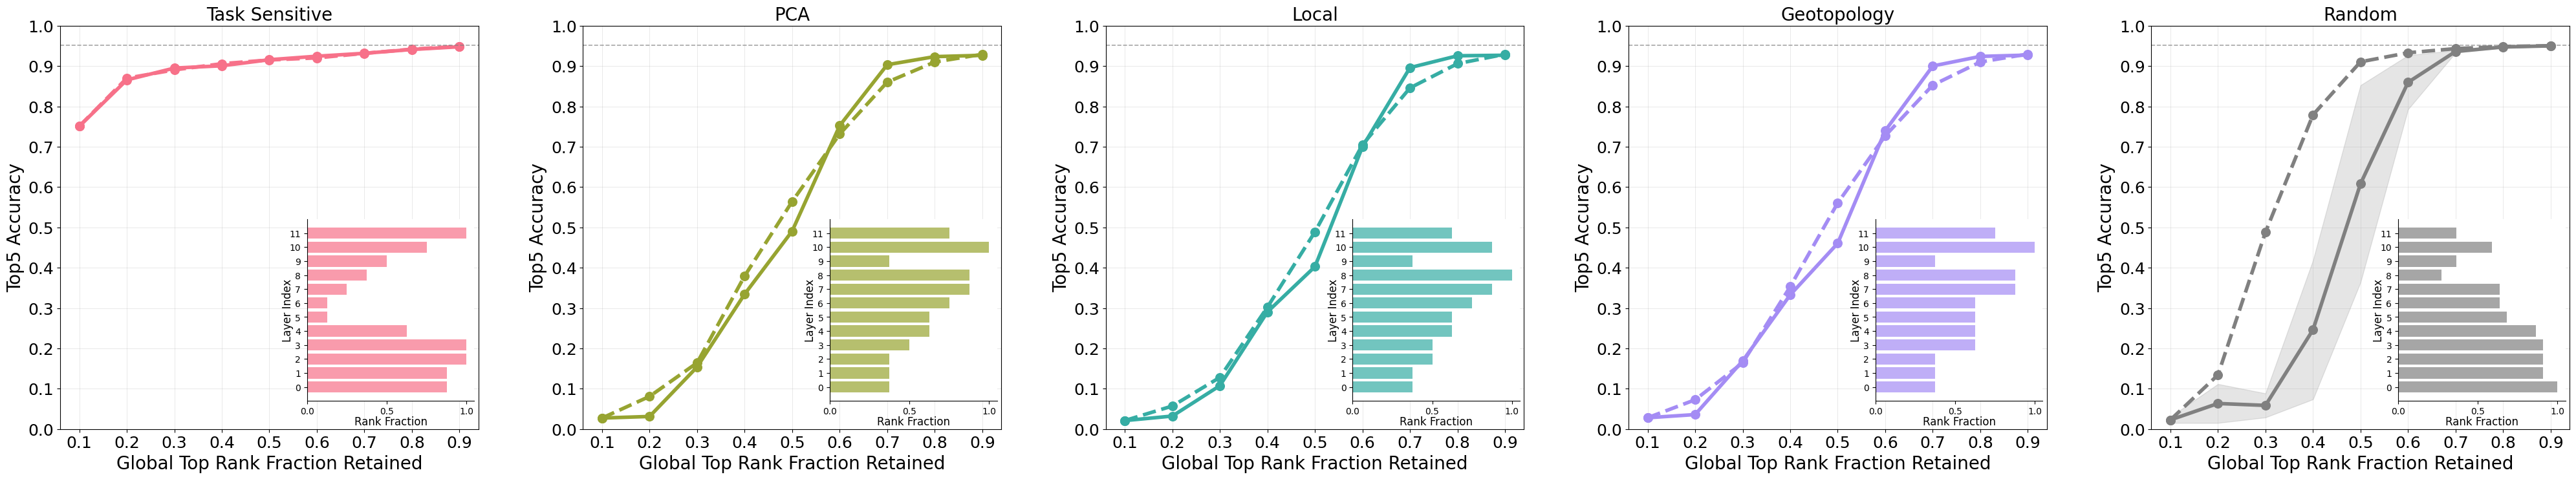

In [8]:
METRIC = 'top5'
ALLOC = 'utility_curve'
RENORM = True

# 1 x 4 grid of global results for each projection type
fig, axs = plt.subplots(1, 5, figsize=(40, 8))
fig.subplots_adjust(
    left=0.025,
    right=0.995,
    bottom=0.14,
    top=0.92,
    wspace=0.25
)
y_lim = [0,1]
renorm_str = "renorm" if RENORM else "raw"
proj_types_with_random = proj_types + ['random']



if ALLOC == 'utility_curve':
    proj_rank_layer_weights = {}
    # add inset graph showing layerwise allocation for this projection type (bottom right)
    for pi, proj_type in enumerate(proj_types_with_random):
        rank_layer_weights = np.zeros((len(layer_inds), len(rank_fracs)))
        for ri, r in enumerate(rank_fracs):
            if proj_type != 'random':
                alloc_df = pd.read_csv(f"{results_dir}/{MODEL_NAME}/allocation/{proj_type}_{ALLOC}_{r}.csv", index_col=0)
                layer_weights = alloc_df.loc[layer_inds, 'k_l']
                rank_layer_weights[:, ri] = layer_weights.values
            else:
                across_seed_weights = []
                for rep_i in range(3):
                    alloc_df = pd.read_csv(f"{results_dir}/{MODEL_NAME}/allocation/random_{ALLOC}_{r}_seed{rep_i}.csv", index_col=0)
                    layer_weights = alloc_df.loc[layer_inds, 'k_l']
                    rank_layer_weights[:, ri] = layer_weights.values
                    across_seed_weights.append(layer_weights.values)
                rank_layer_weights[:, ri] = np.mean(across_seed_weights, axis=0)


            # print(f"{results_dir}/{MODEL_NAME}/allocation/{proj_type}_{ALLOC}_{r}.csv")
            
        proj_rank_layer_weights[proj_type] = rank_layer_weights


for pi, proj_type in enumerate(proj_types_with_random):
    ax = axs[pi]
    if proj_type != 'random':
        global_res = pd.read_csv(f"{results_dir}/{MODEL_NAME}/{proj_type}_global_results/{ALLOC}.csv")
        global_accs = global_res[global_res['condition'] == f'compressed_{renorm_str}'].set_index('retain_fraction_global')[METRIC]
        rank_fracs = extract_rank_fracs_from_data(global_res, global_flag=True)[:-1]
        y_vals = global_accs.values

        ax.plot(
            rank_fracs, global_accs,
            color=proj_colors[pi],
            marker='o', markersize=10,
            markerfacecolor=proj_colors[pi],
            markeredgewidth=0.8,
            linewidth=4,
            label=proj_to_title[proj_type],
        )
        global_res_fixed = pd.read_csv(f"{results_dir}/{MODEL_NAME}/{proj_type}_global_results/fixed.csv")
        global_accs_fixed = global_res_fixed[global_res_fixed['condition'] == f'compressed_{renorm_str}'].set_index('retain_fraction_global')[METRIC]
        y_vals = global_accs_fixed.values

        ax.plot(
            rank_fracs, global_accs_fixed,
            color=proj_colors[pi],
            marker='o', markersize=10,
            linestyle='--',
            markerfacecolor=proj_colors[pi],
            markeredgewidth=0.8,
            linewidth=4,
            label=proj_to_title[proj_type],
        )

    # add random baseline
    else:
        random_y_seeds = []
        random_y_seeds_fixed = []
        for rep_i in range(3):
            global_res = pd.read_csv(f"{results_dir}/{MODEL_NAME}/random_global_results_seed{rep_i}/{ALLOC}.csv")
            global_accs = global_res[global_res['condition'] == f'compressed_{renorm_str}'].set_index('retain_fraction_global')[METRIC]
            random_y_seeds.append(global_accs.values)

            global_res_fixed = pd.read_csv(f"{results_dir}/{MODEL_NAME}/random_global_results_seed{rep_i}/fixed.csv")
            global_accs_fixed = global_res_fixed[global_res_fixed['condition'] == f'compressed_{renorm_str}'].set_index('retain_fraction_global')[METRIC]
            random_y_seeds_fixed.append(global_accs_fixed.values)

        #avg across seeds and error bars for std dev across seeds
        random_y_avg = np.mean(random_y_seeds, axis=0)
        random_y_std = np.std(random_y_seeds, axis=0)
        random_y_avg_fixed = np.mean(random_y_seeds_fixed, axis=0)
        random_y_std_fixed = np.std(random_y_seeds_fixed, axis=0)
        ax.plot(
            rank_fracs, random_y_avg,
            color='gray',
            marker='o', markersize=10,
            markerfacecolor='gray',
            markeredgewidth=0.8,
            linewidth=4,
            label='Random',
            zorder=2,
        )
        ax.fill_between(
            rank_fracs,
            random_y_avg - random_y_std,
            random_y_avg + random_y_std,
            color='gray',
            alpha=0.2,
            zorder=1,
        )
        ax.plot(
            rank_fracs, random_y_avg_fixed,
            color='gray',
            marker='o', markersize=10,
            linestyle='--',
            markerfacecolor='gray',
            markeredgewidth=0.8,
            linewidth=4,
            label='Random Fixed',
            zorder=2,
        )
        # ax.fill_between(
        #     rank_fracs,
        #     random_y_avg_fixed - random_y_std_fixed,
        #     random_y_avg_fixed + random_y_std_fixed,
        #     color='gray',
        #     alpha=0.2,
        #     zorder=1,
        # )
    
    

    if ALLOC == 'utility_curve':
        # inset showing layerwise allocation for this projection type at highest rank fraction
        ax_inset = ax.inset_axes([0.59, 0.07, 0.40, 0.45])  # [x, y, w, h] in axes coords

        ALLOC_RANK_IDX = 4
        layer_weights = proj_rank_layer_weights[proj_type][:, ALLOC_RANK_IDX]  

        # normalize layer weights to sum to 1 for better visualization
        layer_weights = layer_weights / np.max(layer_weights)
        ax_inset.barh(range(len(layer_inds)), layer_weights, color=proj_colors[pi], alpha=0.7)
        ax_inset.set_yticks(range(len(layer_inds)))
        ax_inset.set_yticklabels([str(l) for l in layer_inds], fontsize=6)
        ax_inset.set_xlabel("Rank Fraction", fontsize=12, labelpad=0)
        ax_inset.set_ylabel("Layer Index", fontsize=12, labelpad=-5)


        ax_inset.set_xticks(np.round(np.linspace(0, np.max(layer_weights), 3),1 ))
        ax_inset.set_xticklabels([f"{x:.1f}" for x in ax_inset.get_xticks()], fontsize=10)
        # ax_inset.set_title(f"Allocation @ rank={rank_fracs[ALLOC_RANK_IDX]:.1f}", fontsize=12)

        ax_inset.set_yticks(np.arange(len(layer_inds)))
        ax_inset.set_yticklabels([str(l) for l in layer_inds], fontsize=10)
        ax_inset.spines[['top', 'right']].set_visible(False)


    ax.axhline(BASELINE[METRIC], color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
    ax.grid(True, which='both', linewidth=0.5, alpha=0.4)
    ax.set_xlabel("Global Top Rank Fraction Retained", fontsize=20)
    ax.set_ylabel(f"{METRIC.capitalize()} Accuracy", fontsize=20)
    ax.set_xticks(rank_fracs)
    ax.set_xticklabels([f"{rf:.1f}" for rf in rank_fracs], fontsize=18)

    ax.set_yticks(np.arange(y_lim[0], y_lim[1]+0.1, 0.1))
    ax.set_yticklabels([f"{y:.1f}" for y in np.arange(y_lim[0], y_lim[1]+0.1, 0.1)], fontsize=18)
    
    ax.set_ylim(y_lim)
    ax.legend().remove()
    ax.set_title(f"{proj_to_title[proj_type]}", fontsize=20)

    

# plt.suptitle(f"Global {metric_to_title[METRIC]} Curves for {model_to_title[MODEL_NAME]} - {ALLOC.upper()} Allocation", fontsize=2)
plt.savefig(f"{figures_dir}/main/A3_{MODEL_NAME}_{METRIC}_global_curves.png", dpi=300)
plt.show()


# Supplementary

## Fig SA1 - task performance for many models

In [9]:
MODELS_TO_PLOT = ['vit_b_16', 'vit_s_16', 'vit_ti_16']
PROJ_TYPE = 'task'
METRIC = 'delta_top5'
RENORM = True
results_dir = '../vit_results_v3/'
model_to_title = {
    "vit_b_16": "ViT-B/16",
    "vit_b_32": "ViT-B/32",
    "vit_l_16": "ViT-L/16",
    "vit_l_32": "ViT-L/32",
    "deit3_b_16": "DeiT3-B/16",
    "vit_b_16_in21k": "ViT-B/16 (IN21K)",
    "vit_s_16": "ViT-S/16",
    "vit_ti_16": "ViT-Ti/16"
}


Plotting vit_b_16 - task - delta_top5 heatmap with shape (12, 9)
Plotting vit_s_16 - task - delta_top5 heatmap with shape (12, 9)
Plotting vit_ti_16 - task - delta_top5 heatmap with shape (12, 9)
Plotting vit_b_16 - pca - delta_top5 heatmap with shape (12, 9)
Plotting vit_s_16 - pca - delta_top5 heatmap with shape (12, 9)
Plotting vit_ti_16 - pca - delta_top5 heatmap with shape (12, 9)
Plotting vit_b_16 - random - delta_top5 heatmap with shape (12, 9)
Plotting vit_s_16 - random - delta_top5 heatmap with shape (12, 9)
Plotting vit_ti_16 - random - delta_top5 heatmap with shape (12, 9)


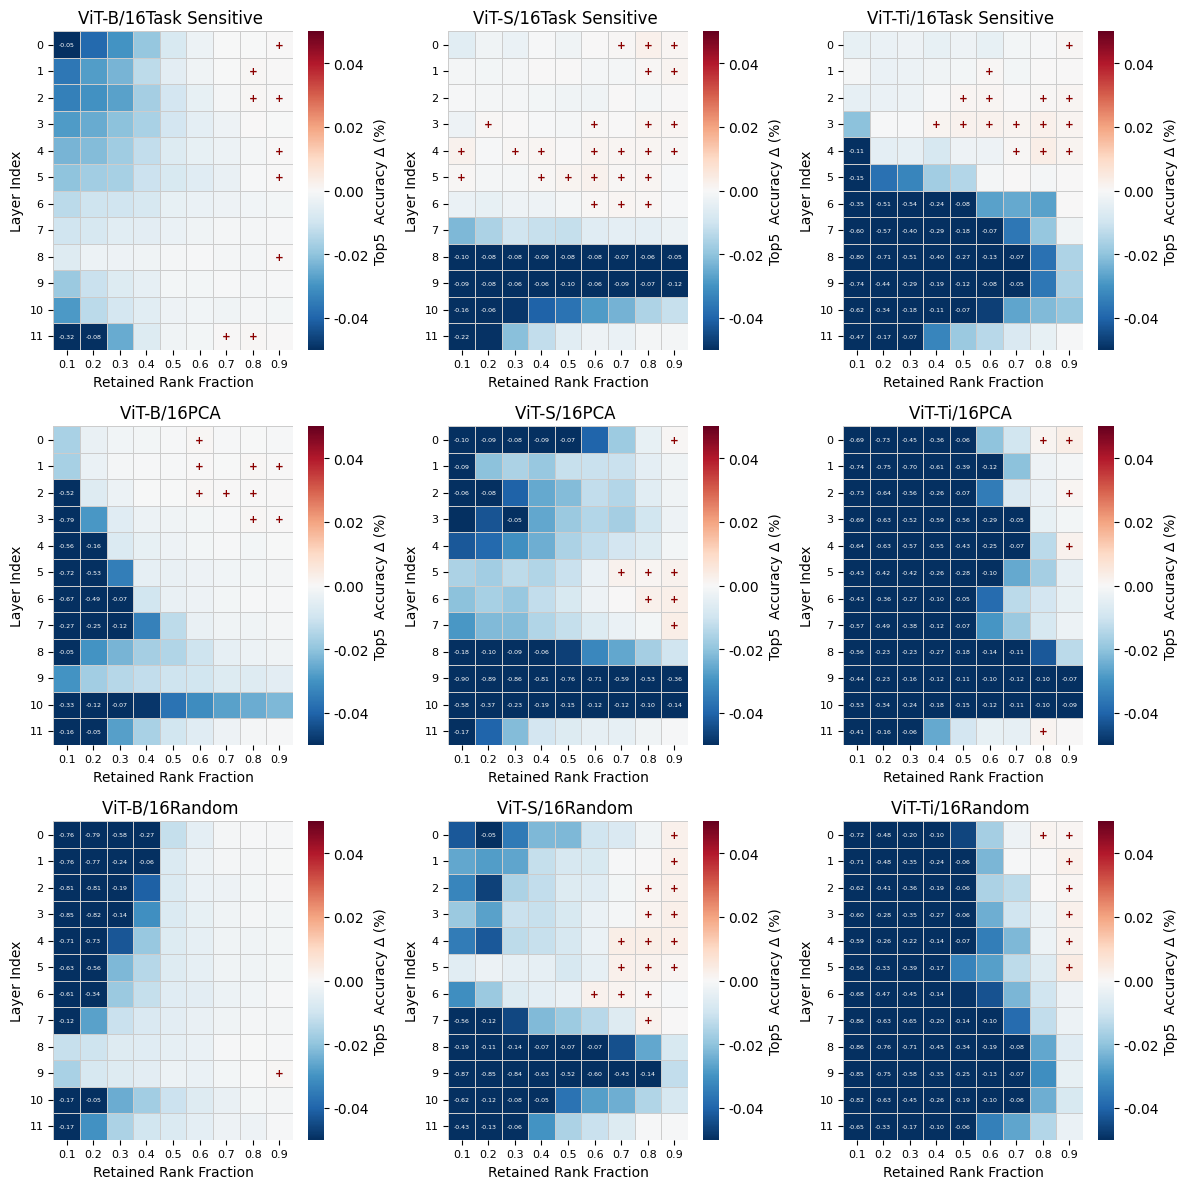

In [11]:

# tight symmetric clim to reveal near-zero structure
clim = 0.05
cmap_limits = [-clim, clim]
projs_to_plot = ['task', 'pca', 'random']
fig, axs = plt.subplots(len(projs_to_plot), len(MODELS_TO_PLOT), figsize=(len(MODELS_TO_PLOT) * 4, len(projs_to_plot) * 4))

for pi in range(len(projs_to_plot)):
    PROJ_TYPE = projs_to_plot[pi]
    for i, model_name in enumerate(MODELS_TO_PLOT):
        
        ax = axs[pi, i]
        if PROJ_TYPE == 'random':
            # for random, average across seeds
            random_res_seeds = []
            for rep_i in range(1):
                result_df_random = pd.read_csv(f"{results_dir}/{model_name}/random_cache_seed{rep_i}/single_layer_random_utility_curves.csv")
                res_random = extract_layer_rank_grid(result_df_random, renorm=RENORM, null_proj=False, metric=METRIC)
                random_res_seeds.append(res_random)
            res = np.mean(random_res_seeds, axis=0)
            layer_inds = extract_layer_inds_from_data(result_df_random)
            rank_fracs = extract_rank_fracs_from_data(result_df_random)
        else:
            result_df = pd.read_csv(f"{results_dir}/{model_name}/{PROJ_TYPE}_cache/single_layer_{proj_to_filename[PROJ_TYPE]}_utility_curves.csv")
            res = extract_layer_rank_grid(result_df, renorm=RENORM, null_proj=False, metric=METRIC)
            layer_inds = extract_layer_inds_from_data(result_df)
            rank_fracs = extract_rank_fracs_from_data(result_df)

        print(f"Plotting {model_name} - {PROJ_TYPE} - {METRIC} heatmap with shape {res.shape}")
        baseline_diff = res 
        sns.heatmap(
            baseline_diff,
            xticklabels=np.round(rank_fracs, 2),
            yticklabels=layer_inds,
            ax=ax,
            cmap='RdBu_r',
            center=0,
            vmin=cmap_limits[0],
            vmax=cmap_limits[1],
            cbar_kws={'label': f'{METRIC.split("_")[1].capitalize()}  Accuracy Δ (%)', 'format': '%.2f'},
            linewidths=0.6,
            linecolor='#cccccc',
        )

        # annotate positive cells with actual value
        for i in range(baseline_diff.shape[0]):
            for j in range(baseline_diff.shape[1]):
                val = baseline_diff[i, j]
                if val > 0:
                    ax.text(j + 0.5, i + 0.5, f'+',
                            ha='center', va='center', color='darkred',
                            fontsize=7.5, fontweight='bold')
                elif val < -clim:
                    # mark clipped cells so reader knows they're saturated
                    ax.text(j + 0.5, i + 0.5, f'{val:.2f}',
                            ha='center', va='center', color='white',
                            fontsize=4.5)

        

        ax.set_title(f"{model_to_title[model_name]}{proj_to_title[PROJ_TYPE]} ", fontsize=12)
        ax.set_xlabel("Retained Rank Fraction")
        ax.set_ylabel("Layer Index")

        ax.tick_params(axis='x', labelrotation=0, labelsize=8)
        ax.tick_params(axis='y', labelrotation=0, labelsize=8)

plt.tight_layout()
plt.savefig(f"{figures_dir}/supp/figSA1_many_models_{PROJ_TYPE}_{METRIC}_heatmaps.png", dpi=300)
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from utilz.plotting_utilz import * 

In [ ]:
results_dir = "../vit_results_v3/"
figures_dir = "./paper_figs_v2/"

FileNotFoundError: [Errno 2] No such file or directory: '../vit_results_v3//deit3_b_16/local_global_results/utility_curve.csv'

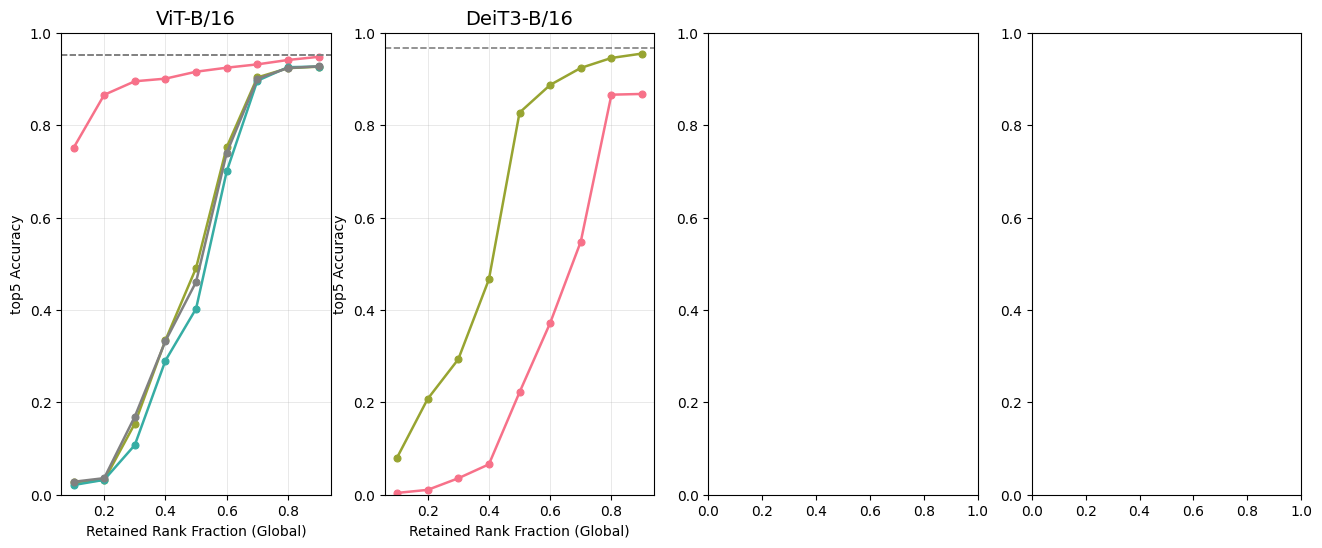

In [ ]:
METRIC = 'top5'
ALLOC = 'utility_curve'
RENORM = True

# 1 x 4 grid of global results for each model with each projection type as lines
fig, axs = plt.subplots(1, len(MODELS_TO_PLOT), figsize=(len(MODELS_TO_PLOT) * 4, 6))
y_lim = [0,1]
renorm_str = "renorm" if RENORM else "raw"
# proj_types_with_random = proj_types + ['random']
proj_to_plot = ['task', 'pca', 'local', 'gt']
proj_colors_to_plot = proj_colors[:len(proj_to_plot)-1] + ['gray']  # ensure colors align with proj_to_plot
for mi, model_name in enumerate(MODELS_TO_PLOT):
    ax = axs[mi]

    for pi, proj_type in enumerate(proj_to_plot):
        if proj_type != 'random':
            global_res = pd.read_csv(f"{results_dir}/{model_name}/{proj_type}_global_results/{ALLOC}.csv")
            baseline = global_res.iloc[0][f'{METRIC}']
            global_accs = global_res[global_res['condition'] == f'compressed_{renorm_str}'].set_index('retain_fraction_global')[METRIC]
            rank_fracs = extract_rank_fracs_from_data(global_res, global_flag=True)[:-1]
            y_vals = global_accs.values

            ax.plot(
                rank_fracs, global_accs,
                color=proj_colors_to_plot[pi],
                marker='o', markersize=5,
                markerfacecolor=proj_colors_to_plot[pi],
                markeredgewidth=0.8,
                linewidth=1.8,
                label=proj_to_title[proj_type],
            )

        # add random baseline
        else:
            random_y_seeds = []
            for rep_i in range(1):
                global_res = pd.read_csv(f"{results_dir}/{model_name}/random_global_results_seed{rep_i}/{ALLOC}.csv")
                global_accs = global_res[global_res['condition'] == f'compressed_{renorm_str}'].set_index('retain_fraction_global')[METRIC]
                random_y_seeds.append(global_accs.values)

            #avg across seeds and error bars for std dev across seeds
            random_y_avg = np.mean(random_y_seeds, axis=0)
            random_y_std = np.std(random_y_seeds, axis=0)
            ax.plot(
                rank_fracs, random_y_avg,
                color='gray',
                marker='o', markersize=5,
                markerfacecolor='gray',
                markeredgewidth=0.8,
                linewidth=1.8,
                label='Random Baseline',
                zorder=2,
            )
            ax.fill_between(
                rank_fracs,
                random_y_avg - random_y_std,
                random_y_avg + random_y_std,
                color='gray',
                alpha=0.2,
                zorder=1,
            )
        
        
        ax.axhline(baseline, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
        ax.grid(True, which='both', linewidth=0.5, alpha=0.4)
        ax.set_title(f"{model_to_title[model_name]}", fontsize=14)
        ax.set_xlabel("Retained Rank Fraction (Global)")
        ax.set_ylabel(f"{METRIC} Accuracy")
        ax.set_ylim(y_lim)
        ax.legend().remove()

handles = [plt.Line2D([0], [0], color=proj_colors_to_plot[pi], marker='o', markersize=8, label=proj_to_title[proj_type]) for pi, proj_type in enumerate(proj_to_plot)]
fig.legend(handles=handles, loc='lower center', ncol=len(proj_to_plot), fontsize=14)
plt.suptitle(f"Global {metric_to_title[METRIC]} Curves - {ALLOC.upper()} Allocation", fontsize=16)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
# plt.savefig(f"{figures_dir}/supp/figSA6_many_models_{METRIC}_global_{ALLOC}_curves.png", dpi=300)
plt.show()


## Fig SA2 - layerwise curves with rand baseline

## Fig SA3 - Global acc curve with random global baseline

## Fig SA4 - all proj heatmaps + rand + null

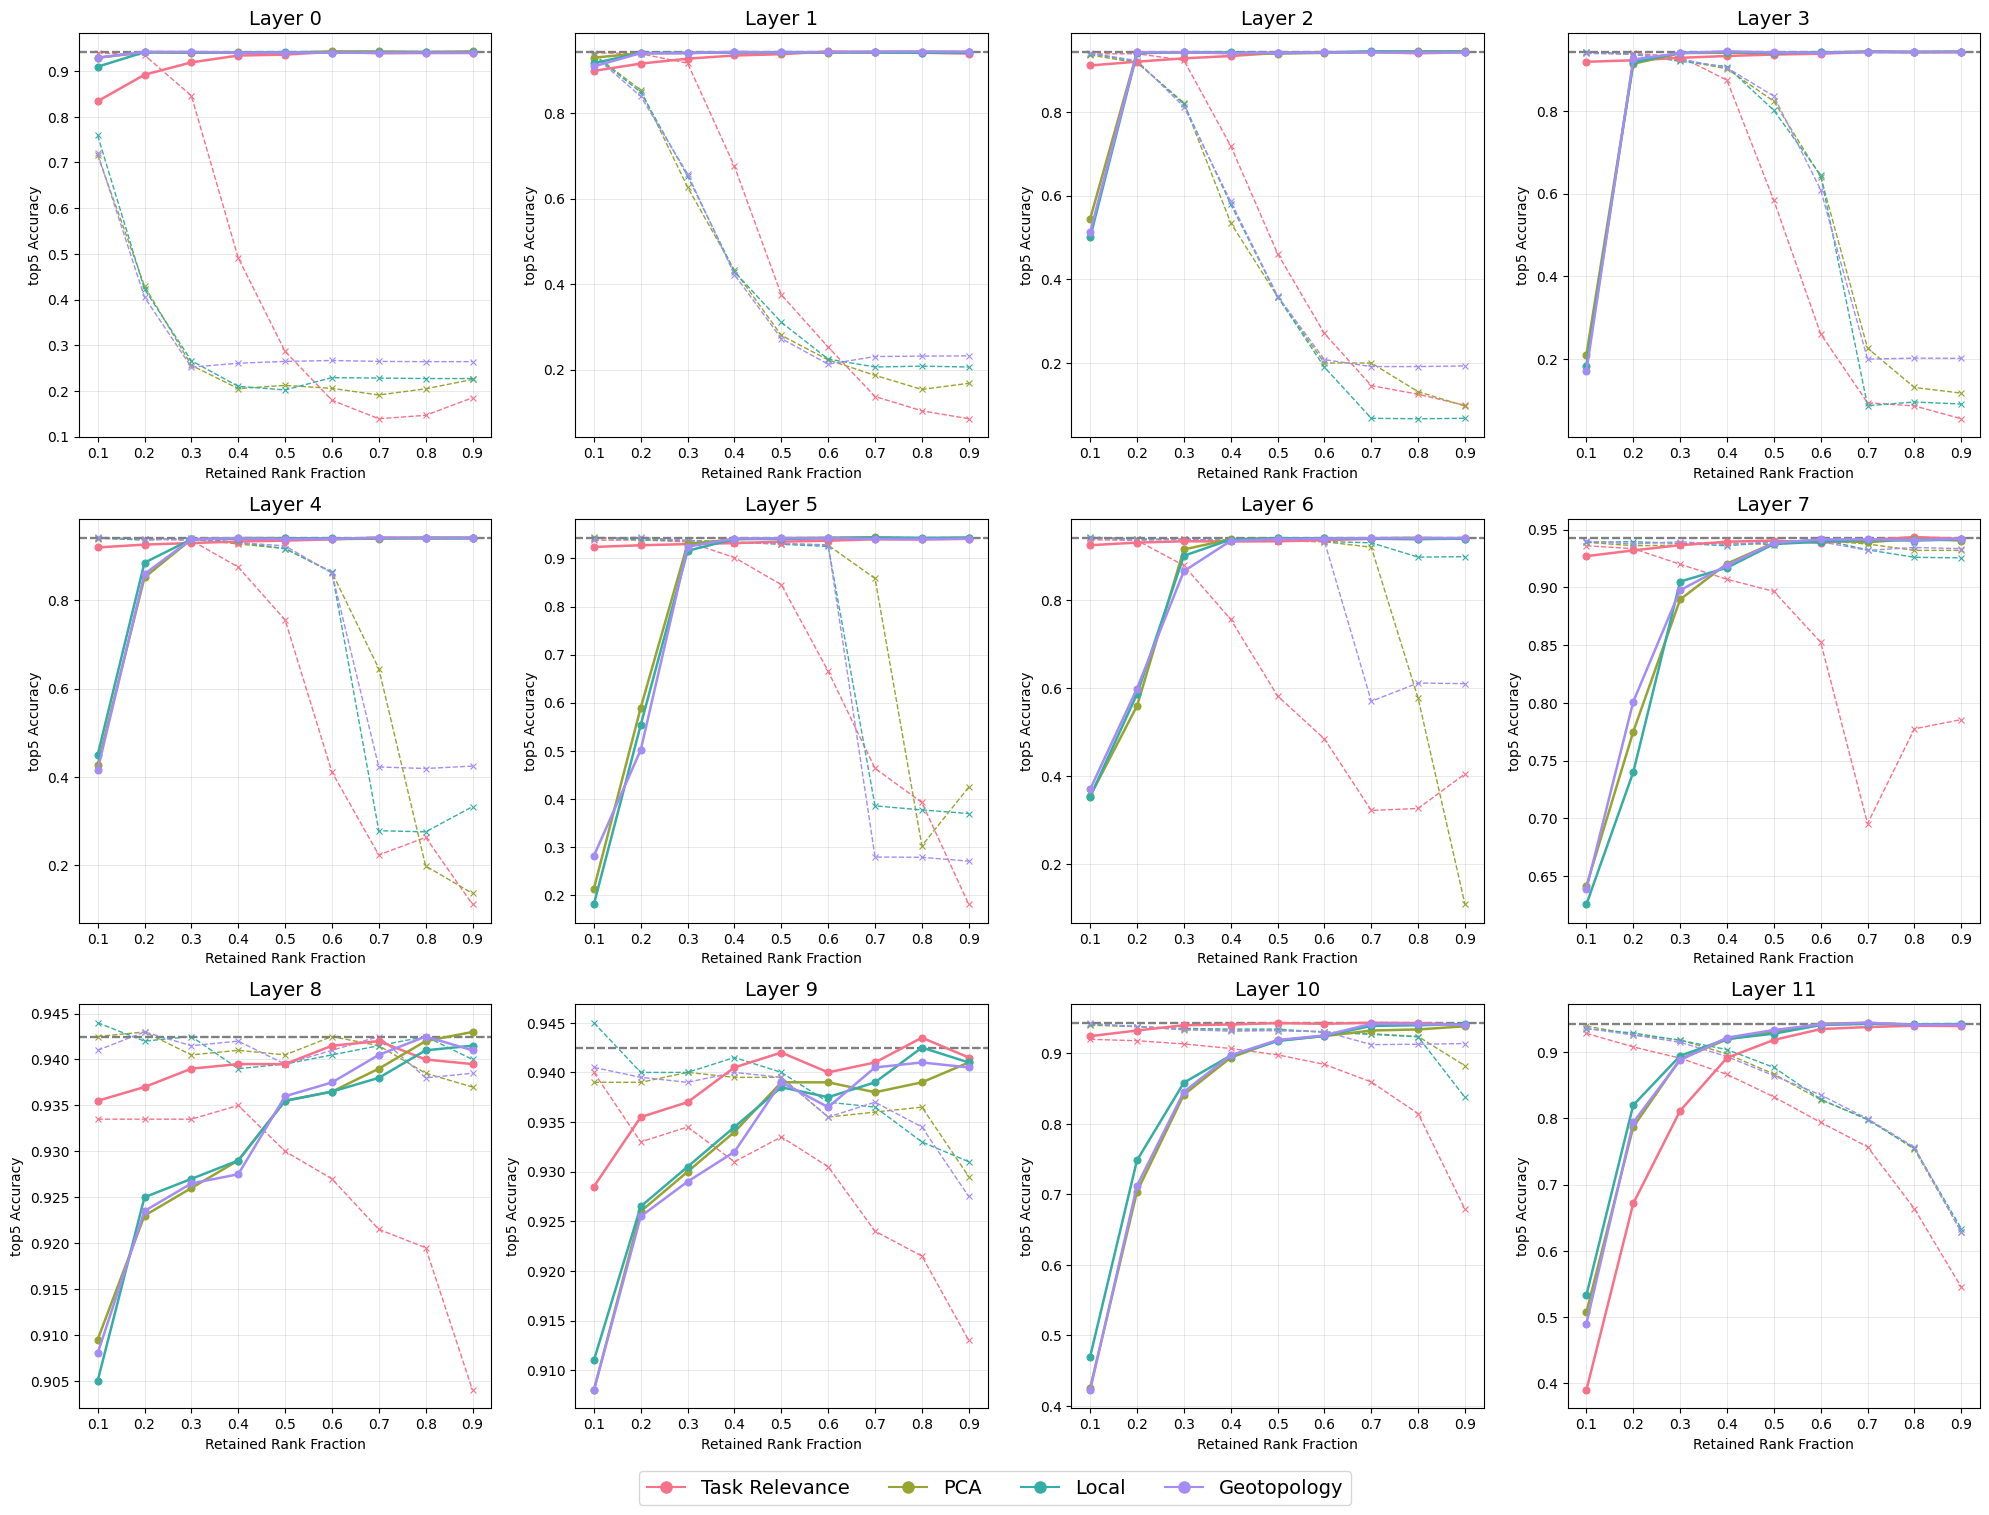

In [ ]:
# n_layer grids for rankwise curves, one for each projection type

fig, axs = plt.subplots(3,4, figsize=(20, 16))

for li in layer_inds:
    ax = axs[li // 4, li % 4]
    plus_count = np.zeros(len(rank_fracs), dtype=int)

    for pi, proj_type in enumerate(proj_types):
        result_df = pd.read_csv(f"{results_dir}/{MODEL_NAME}/{proj_type}_cache/single_layer_{proj_to_filename[proj_type]}_utility_curves.csv")
        res_scores = extract_layer_rank_grid(result_df, renorm=RENORM, null_proj=False, metric=METRIC)
        null_res_scores = extract_layer_rank_grid(result_df, renorm=RENORM, null_proj=True, metric=METRIC)
       
        y_vals = res_scores[li]
        ax.plot(
            rank_fracs, y_vals,
            color=proj_colors[pi],
            marker='o', markersize=5,
            markerfacecolor=proj_colors[pi],
            markeredgewidth=0.8,
            linewidth=1.8,
            label=proj_to_title[proj_type],
            zorder=3,
        )
        ax.plot(
            rank_fracs, null_res_scores[li],
            color=proj_colors[pi],
            marker='x', markersize=5,
            linestyle='--',
            markerfacecolor=proj_colors[pi],
            markeredgewidth=0.8,
            linewidth=1,
            label=f'Null {proj_to_title[proj_type]}',
            zorder=2,
        )

        # add horizontal line for baseline
        ax.axhline(BASELINE[METRIC], color='gray', linestyle='--', label='Baseline')

        # add grid
        ax.grid(True, which='both', linewidth=0.5, alpha=0.4)
        ax.set_title(f"Layer {li}", fontsize=14)
        ax.set_xlabel("Retained Rank Fraction")
        ax.set_ylabel(f"{METRIC} Accuracy")

        # remove legend
        ax.legend().remove()
    
handles = [plt.Line2D([0], [0], color=proj_colors[pi], marker='o', markersize=8, label=proj_to_title[proj_type]) for pi, proj_type in enumerate(proj_types)]
fig.legend(handles=handles, loc='lower center', ncol=len(proj_types), fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(f"{figures_dir}/supp/fig_SA2_{MODEL_NAME}_{METRIC}_layerwise_curves_with_null.png", dpi=300)
plt.show() 
    

### Heatmaps for each proj type and complementary

In [ ]:
result_df = pd.read_csv(f"{results_dir}/{MODEL_NAME}/{proj_type}_cache/single_layer_{proj_to_filename[proj_type]}_utility_curves.csv")
result_df.columns

Index(['layer_index', 'hidden_dim', 'rank', 'retain_fraction_layer',
       'retained_geotopology_mass', 'total_geotopology_mass',
       'retained_geotopology_mass_fraction', 'top1_raw', 'top5_raw',
       'top1_renorm', 'top5_renorm', 'top1_null_raw', 'top5_null_raw',
       'top1_null_renorm', 'top5_null_renorm'],
      dtype='str')

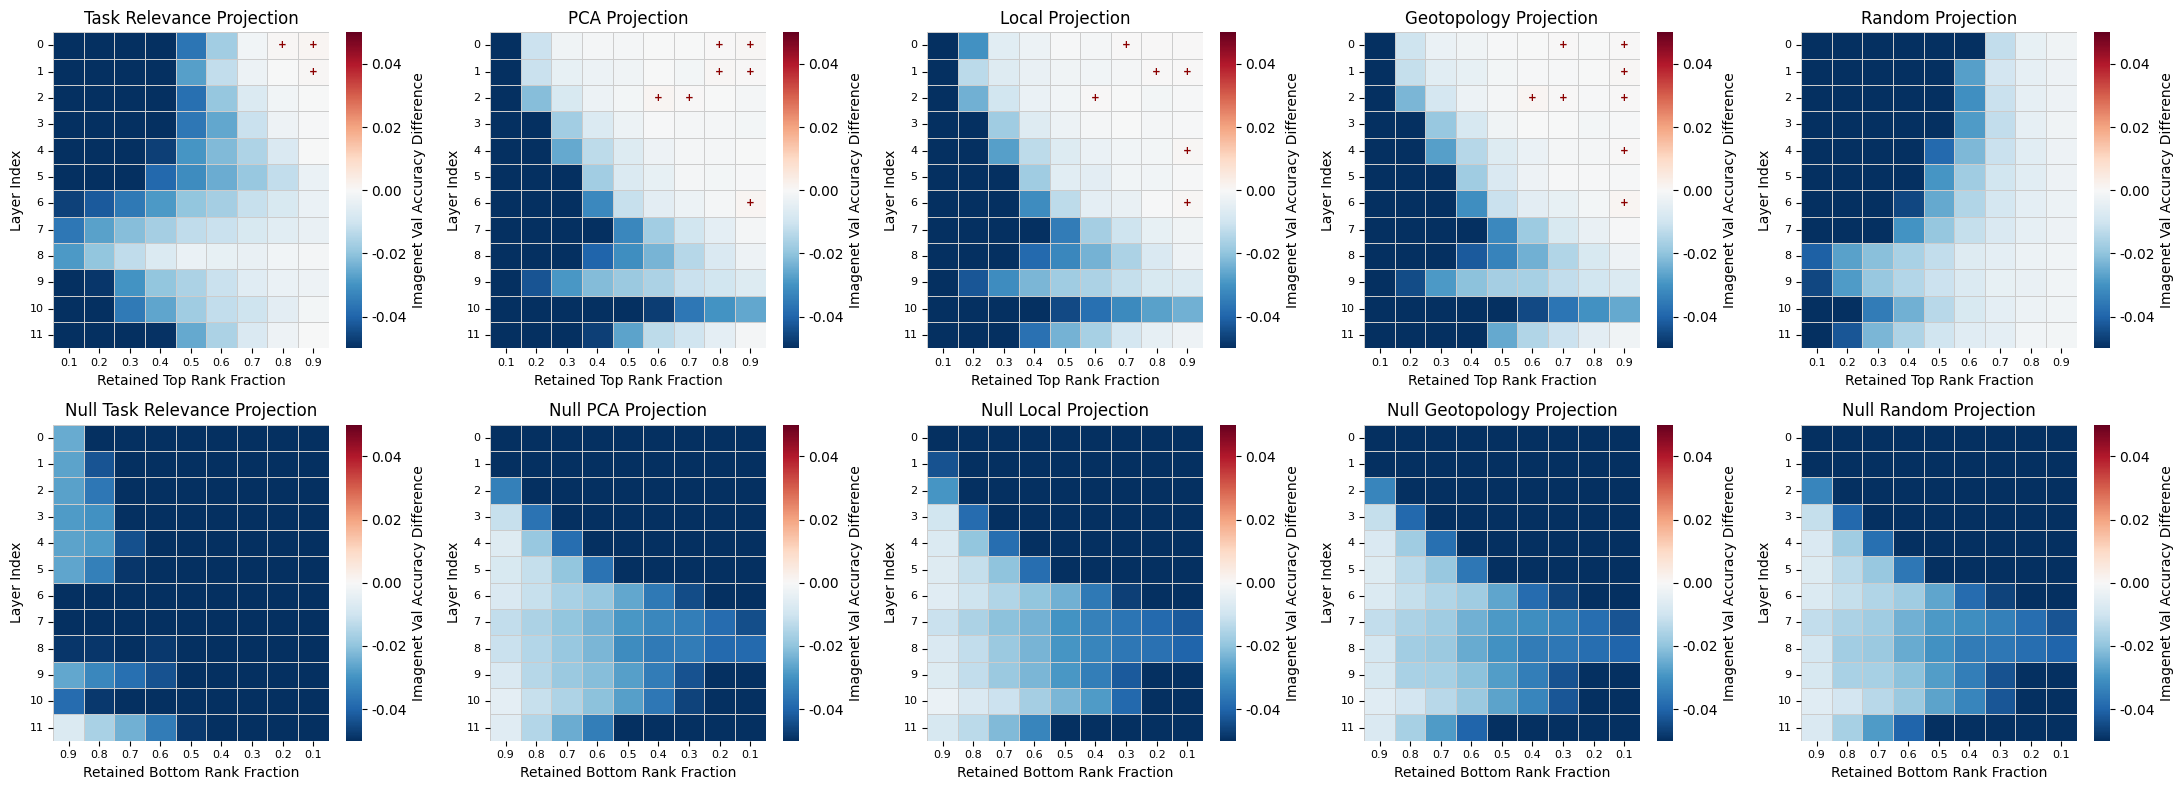

In [ ]:
# 2x4 grid - first row is projection results, second row is null projection results
clim = 0.05
cmap_limits = [-clim, clim]
METRIC = 'top1'
RENORM = True

projs_to_plot = ['task', 'pca', 'local', 'gt', 'random']
fig, axes = plt.subplots(2, 5, figsize=(22, 8))

for pi, proj_type in enumerate(projs_to_plot):
    ax = axes[0, pi % 5]

    if proj_type != 'random':
        result_df = pd.read_csv(f"{results_dir}/{MODEL_NAME}/{proj_type}_cache/single_layer_{proj_to_filename[proj_type]}_utility_curves.csv")
        res = extract_layer_rank_grid(result_df, renorm=RENORM, null_proj=False, metric=METRIC)
        baseline_diff = res - BASELINE[METRIC]


    elif proj_type == 'random':
        baseline_diff_random_seeds = []
        for rep_i in range(3):
            result_df_random = pd.read_csv(f"{results_dir}/{MODEL_NAME}/random_cache_seed{rep_i}/single_layer_random_utility_curves.csv")
            res_random = extract_layer_rank_grid(result_df_random, renorm=RENORM, null_proj=False, metric=METRIC)
            baseline_diff_random = res_random - BASELINE[METRIC]
            baseline_diff_random_seeds.append(baseline_diff_random)
        baseline_diff= np.mean(baseline_diff_random_seeds, axis=0)


    sns.heatmap(
        baseline_diff,
        xticklabels=np.round(rank_fracs, 2),
        yticklabels=layer_inds,
        ax=ax,
        cmap='RdBu_r',
        center=0,
        vmin=cmap_limits[0],
        vmax=cmap_limits[1],
        cbar_kws={'label': f'Imagenet Val Accuracy Difference', 'format': '%.2f'},
        linewidths=0.6,
        linecolor='#cccccc',
    )
    

    # # annotate positive cells with actual value
    for i in range(baseline_diff.shape[0]):
        for j in range(baseline_diff.shape[1]):
            val = baseline_diff[i, j]
            if val > 0:
                ax.text(j + 0.5, i + 0.5, f'+',
                        ha='center', va='center', color='darkred',
                        fontsize=7.5, fontweight='bold')
            # elif val < -clim:
            #     # mark clipped cells so reader knows they're saturated
            #     ax.text(j + 0.5, i + 0.5, f'{val:.2f}',
            #             ha='center', va='center', color='white',
            #             fontsize=7.5)


    ## NULL PROJECTION HEATMAPS
    ax.set_title(f"{proj_to_title[proj_type]} Projection", fontsize=12)
    ax.set_xlabel("Retained Top Rank Fraction")
    ax.set_ylabel("Layer Index")

    ax.tick_params(axis='x', labelrotation=0, labelsize=8)
    ax.tick_params(axis='y', labelrotation=0, labelsize=8)

    if proj_type != 'random':
        result_df = pd.read_csv(f"{results_dir}/{MODEL_NAME}/{proj_type}_cache/single_layer_{proj_to_filename[proj_type]}_utility_curves.csv")
        null_res = extract_layer_rank_grid(result_df, renorm=RENORM, null_proj=True, metric=METRIC)
        null_baseline_diff  = null_res - BASELINE[METRIC]


    elif proj_type == 'random':
        null_baseline_diff_random_seeds = []
        for rep_i in range(3):
            result_df_random = pd.read_csv(f"{results_dir}/{MODEL_NAME}/random_cache_seed{rep_i}/single_layer_random_utility_curves.csv")
            null_res_random = extract_layer_rank_grid(result_df_random, renorm=RENORM, null_proj=True, metric=METRIC)
            null_baseline_diff_random = null_res_random - BASELINE[METRIC]
            null_baseline_diff_random_seeds.append(null_baseline_diff_random)
        null_baseline_diff = np.mean(null_baseline_diff_random_seeds, axis=0)



    ax = axes[1, pi % 5]
    null_res = extract_layer_rank_grid(result_df, renorm=RENORM, null_proj=True, metric=METRIC)
    null_baseline_diff = null_res - BASELINE[METRIC]

    null_rank_fracs = 1 - rank_fracs
    sns.heatmap(
        null_baseline_diff,
        xticklabels=np.round(null_rank_fracs, 2),
        yticklabels=layer_inds,
        ax=ax,
        cmap='RdBu_r',
        center=0,
        vmin=cmap_limits[0],
        vmax=cmap_limits[1],
        cbar_kws={'label': f'Imagenet Val Accuracy Difference', 'format': '%.2f'},
        linewidths=0.6,
        linecolor='#cccccc',
    )
    
    # # annotate positive cells with actual value
    for i in range(null_baseline_diff.shape[0]):
        for j in range(null_baseline_diff.shape[1]):
            val = null_baseline_diff[i, j]
            if val > 0:
                ax.text(j + 0.5, i + 0.5, f'+',
                        ha='center', va='center', color='darkred',
                        fontsize=7.5, fontweight='bold')
            # elif val < -clim:
            #     # mark clipped cells so reader knows they're saturated
            #     ax.text(j + 0.5, i + 0.5, f'{val:.2f}',
            #             ha='center', va='center', color='white',
            #             fontsize=7.5)



    ax.set_title(f"Null {proj_to_title[proj_type]} Projection", fontsize=12)
    ax.set_xlabel("Retained Bottom Rank Fraction")
    ax.set_ylabel("Layer Index")

    ax.tick_params(axis='x', labelrotation=0, labelsize=8)
    ax.tick_params(axis='y', labelrotation=0, labelsize=8)

plt.tight_layout()
plt.savefig(f"{figures_dir}/supp/SA4_{MODEL_NAME}_{METRIC}_heatmaps_proj_null_with_rand.png", dpi=300)
plt.show()

## Comparison with other models

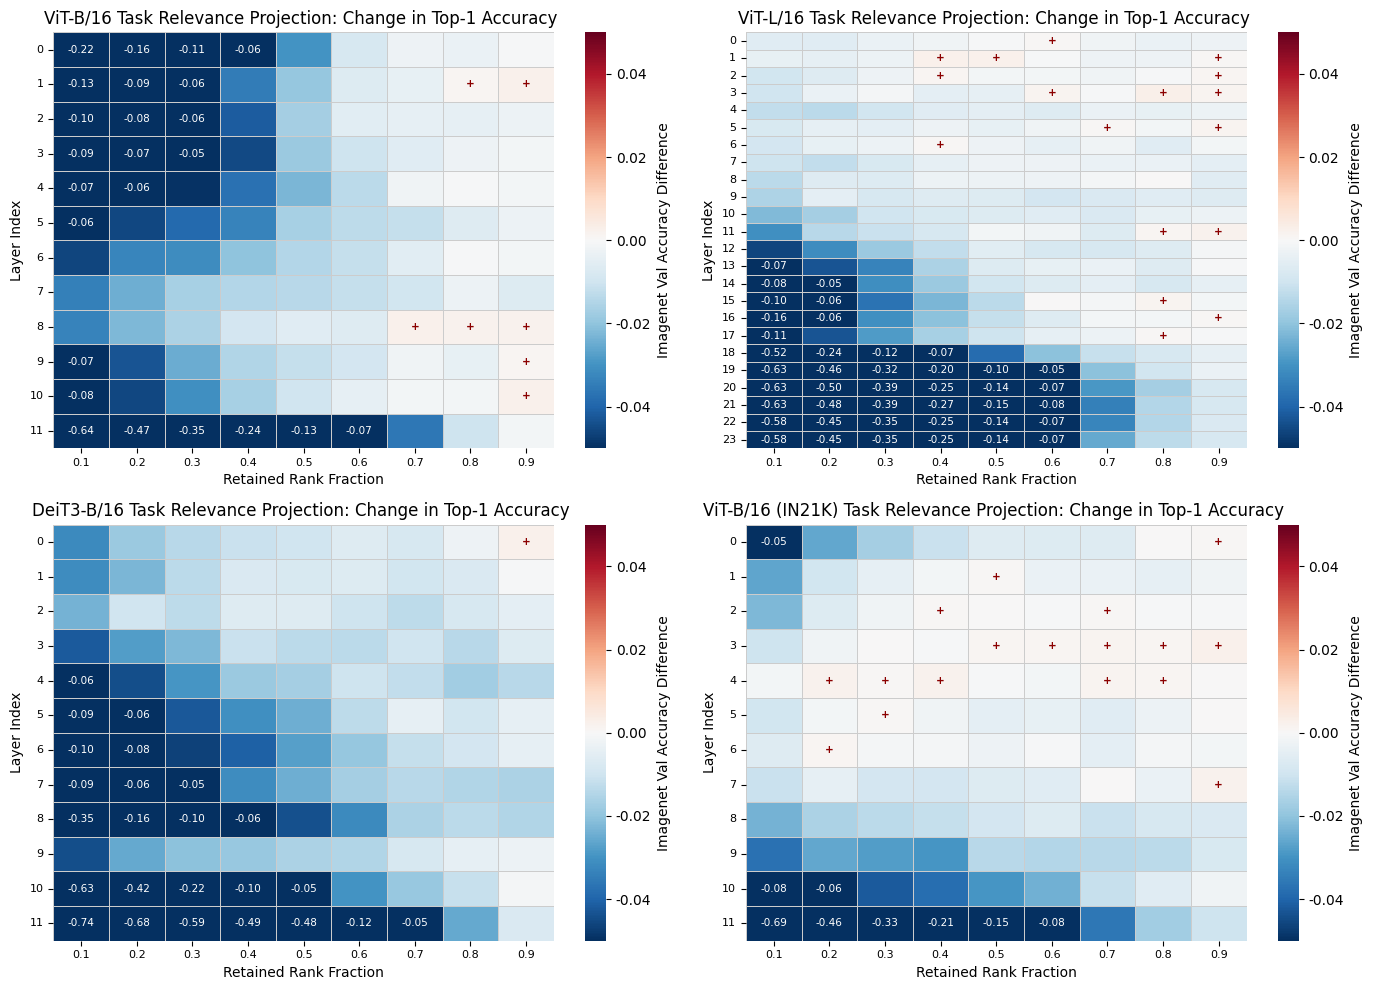

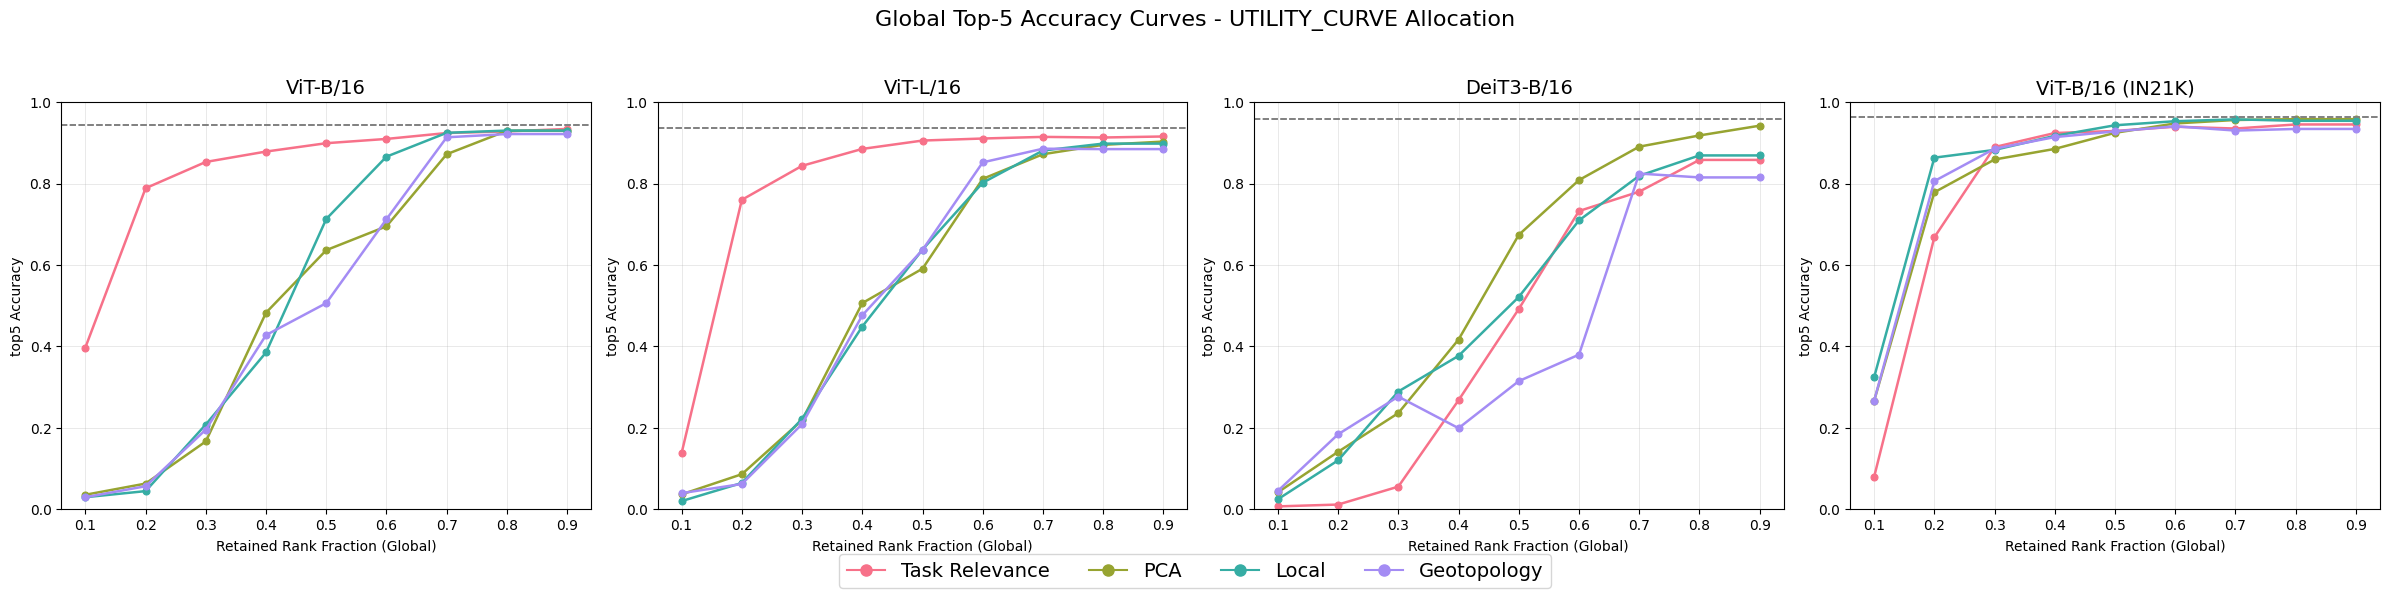